#**Base de Dados - Geração Fotovoltaica**

**PVGIS - Photovoltaic Geographical Information Systems**

- Base de Dados do PVGIS para obtenção dos dados meteológicos históricos de Londres e contrução de perfis de gração PV.
- Informações de radiação solar, meteorologia e estimativas de desempenho de distemas fotovoltaicos

# **Inicialização**




In [2]:
!pip install pvlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 100.6 MB/s  0:00:00


In [3]:
import pvlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# **Dados Metreológicos históricos**

- Utilização da biblioteca .pvlib, módulo iotools, para acessar os dados históricos do PVGIS

- Dados obtidos: Irradiação Solar(global, direta normal e difusa horizontal), Temperatura do Ar e Velocidade do Vento

**Definição do Lugar e Intervalo de Tempo**

In [4]:
# Localização: Londres
latitude = 51.5085
longitude = -0.1276

# Período histórico
start_year = 2012
end_year = 2014

#Definição dos parâmetros dos módulos solares
surface_tilt = 35
surface_azimuth = 180

#Base da radiação utilizada --> PVGIS-SARAH3
#Base da radiação meteorologica --> ERA5

**Obtenção dos dados meterológicos: PVGIS**

In [5]:
weather, metadata = pvlib.iotools.get_pvgis_hourly(
    latitude=latitude,
    longitude=longitude,
    start=start_year,
    end=end_year,
    surface_tilt=surface_tilt,
    surface_azimuth=surface_azimuth,
    usehorizon=True,
    map_variables=True)

print(weather.head())

                           poa_direct  poa_sky_diffuse  poa_ground_diffuse  \
time                                                                         
2012-01-01 00:10:00+00:00         0.0              0.0                 0.0   
2012-01-01 01:10:00+00:00         0.0              0.0                 0.0   
2012-01-01 02:10:00+00:00         0.0              0.0                 0.0   
2012-01-01 03:10:00+00:00         0.0              0.0                 0.0   
2012-01-01 04:10:00+00:00         0.0              0.0                 0.0   

                           solar_elevation  temp_air  wind_speed  Int  
time                                                                   
2012-01-01 00:10:00+00:00              0.0     11.09        4.97    0  
2012-01-01 01:10:00+00:00              0.0     11.29        5.03    0  
2012-01-01 02:10:00+00:00              0.0     11.39        5.03    0  
2012-01-01 03:10:00+00:00              0.0     11.48        4.97    0  
2012-01-01 04:10:00+0

In [6]:
print("Colunas disponíveis:")
print(weather.columns.tolist())

print("\nPrimeiras linhas:")
display(weather.head())

print("\nÚltimas linhas:")
display(weather.tail())

print("\nPeríodo dos dados:")
print(weather.index.min(), "até", weather.index.max())

print("\nQuantidade de registros:")
print(len(weather))

Colunas disponíveis:
['poa_direct', 'poa_sky_diffuse', 'poa_ground_diffuse', 'solar_elevation', 'temp_air', 'wind_speed', 'Int']

Primeiras linhas:


,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
time,,,,,,,
2012-01-01 00:10:00+00:00,0.0,0.0,0.0,0.0,11.09,4.97,0
2012-01-01 01:10:00+00:00,0.0,0.0,0.0,0.0,11.29,5.03,0
2012-01-01 02:10:00+00:00,0.0,0.0,0.0,0.0,11.39,5.03,0
2012-01-01 03:10:00+00:00,0.0,0.0,0.0,0.0,11.48,4.97,0
2012-01-01 04:10:00+00:00,0.0,0.0,0.0,0.0,11.48,4.97,0



Últimas linhas:


,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
time,,,,,,,
2014-12-31 19:10:00+00:00,0.0,0.0,0.0,0.0,4.77,4.28,0
2014-12-31 20:10:00+00:00,0.0,0.0,0.0,0.0,5.02,4.28,0
2014-12-31 21:10:00+00:00,0.0,0.0,0.0,0.0,4.96,4.34,0
2014-12-31 22:10:00+00:00,0.0,0.0,0.0,0.0,4.86,4.41,0
2014-12-31 23:10:00+00:00,0.0,0.0,0.0,0.0,4.65,4.41,0



Período dos dados:
2012-01-01 00:10:00+00:00 até 2014-12-31 23:10:00+00:00

Quantidade de registros:
26304


### **Preparação e validação dos Dados**

In [7]:
# Quantidade de registros por ano
print(weather.groupby(weather.index.year).size())

time
2012    8784
2013    8760
2014    8760
dtype: int64


In [8]:
# Verifica valores ausentes
print("Valores ausentes por coluna:")
print(weather.isnull().sum())

Valores ausentes por coluna:
poa_direct            0
poa_sky_diffuse       0
poa_ground_diffuse    0
solar_elevation       0
temp_air              0
wind_speed            0
Int                   0
dtype: int64


**Detalhes da base de dados trabalhada**
- Intervalos de 1h entre as medições
- Período completo de 2012-2014
- Infos sobre as condições ambientais em que o sistema fotovoltaico estaria submetido

In [9]:
# Estatísticas descritivas
display(weather.describe())

,poa_direct,poa_sky_diffuse,poa_ground_diffuse,solar_elevation,temp_air,wind_speed,Int
count,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.000000,26304.0
mean,73.301921,66.518222,2.169846,12.734264,10.519098,3.507219,0.0
std,168.992759,95.385733,3.506150,17.357856,6.006047,1.715650,0.0
min,0.000000,0.000000,0.000000,0.000000,-5.840000,0.000000,0.0
25%,0.000000,0.000000,0.000000,0.000000,6.277500,2.210000,0.0
50%,0.000000,0.000000,0.000000,0.000000,10.510000,3.240000,0.0
75%,29.342500,118.170000,3.110000,22.560000,14.830000,4.550000,0.0
max,960.580000,419.470000,16.780000,61.880000,30.360000,13.030000,0.0


## **Modelação do Sistema Fotovoltaico com PvLib**

- Potência de referência: 1kWh
- Orientação placas solares: Sul (0* PVGIS)

**Definição da irradiância global pela soma das componentes de irradiância**
- Gg = Gd + Gdf + Gr
Potência gerada depende da quantidade de radiação que incide sobre o painel

**Estimativa das temperaturas das células por meio do Modelo Térmico de Faiman da .pvlib**
- Temperatura influência no desempenho dos módulos e consequentemente na potência gerada

Tm = Ta + (Gg/(U0 + U1.v))
- Temp ambiente, Irradiância global e velocidade do vento estimam a temperatura do módulo


In [10]:
# Irradiância total no plano do painel
weather["poa_global"] = (weather["poa_direct"] +weather["poa_sky_diffuse"] +weather["poa_ground_diffuse"])

# Estimativa da temperatura das células fotovoltaicas
weather["temp_cell"] = pvlib.temperature.faiman(
    poa_global=weather["poa_global"],
    temp_air=weather["temp_air"],
    wind_speed=weather["wind_speed"]
)

# Parâmetros do sistema fotovoltaico

# Potência nominal: 1 kWp (em W)
pdc0 = 1000
# Coeficiente de temperatura (1/°C)
gamma_pdc = -0.0035

display(weather[["poa_global","temp_air","wind_speed","temp_cell"]].head(10))

,poa_global,temp_air,wind_speed,temp_cell
time,,,,
2012-01-01 00:10:00+00:00,0.00,11.09,4.97,11.090000
2012-01-01 01:10:00+00:00,0.00,11.29,5.03,11.290000
2012-01-01 02:10:00+00:00,0.00,11.39,5.03,11.390000
2012-01-01 03:10:00+00:00,0.00,11.48,4.97,11.480000
2012-01-01 04:10:00+00:00,0.00,11.48,4.97,11.480000
2012-01-01 05:10:00+00:00,0.00,11.35,4.90,11.350000
2012-01-01 06:10:00+00:00,0.00,11.23,4.97,11.230000
2012-01-01 07:10:00+00:00,0.00,11.18,4.62,11.180000
2012-01-01 08:10:00+00:00,0.00,11.10,4.62,11.100000


## **Calculo da Potência Fotovoltaica**

Criação da série temporal de potência DC para um sistema fotovoltaico de referência de 1kWp (2021-2014)
- estimativa simplificada (sem modelo de inversor) - painel horizontal
- Modelo pvwatts_dc() .pvlib - para estimar a potência elétrica DC produzida pelo sistema fotovoltaico



In [11]:
# Calcula a potência DC gerada pelo sistema fotovoltaico
weather["pv_power"] = pvlib.pvsystem.pvwatts_dc(
    effective_irradiance=weather["poa_global"],
    temp_cell=weather["temp_cell"],
    pdc0=pdc0,
    gamma_pdc=gamma_pdc
)

# Limita valores negativos a zero
weather["pv_power"] = weather["pv_power"].clip(lower=0)

display(weather[["poa_global","temp_cell","pv_power"]].head(15))

,poa_global,temp_cell,pv_power
time,,,
2012-01-01 00:10:00+00:00,0.00,11.090000,0.000000
2012-01-01 01:10:00+00:00,0.00,11.290000,0.000000
2012-01-01 02:10:00+00:00,0.00,11.390000,0.000000
2012-01-01 03:10:00+00:00,0.00,11.480000,0.000000
2012-01-01 04:10:00+00:00,0.00,11.480000,0.000000
2012-01-01 05:10:00+00:00,0.00,11.350000,0.000000
2012-01-01 06:10:00+00:00,0.00,11.230000,0.000000
2012-01-01 07:10:00+00:00,0.00,11.180000,0.000000
2012-01-01 08:10:00+00:00,0.00,11.100000,0.000000


In [30]:
# Estatísticas da potência fotovoltaica
print("Potência fotovoltaica (W):")
print(weather["pv_power"].describe())

print("\nPotência máxima (kW):")
print(weather["pv_power"].max() / 1000)

Potência fotovoltaica (W):
count    26304.000000
mean       141.575221
std        232.488355
min          0.000000
25%          0.000000
50%          0.000000
75%        188.387280
max       1064.963089
Name: pv_power, dtype: float64

Potência máxima (kW):
1.0649630892539161


# **Contrução das Curvas de Geração**

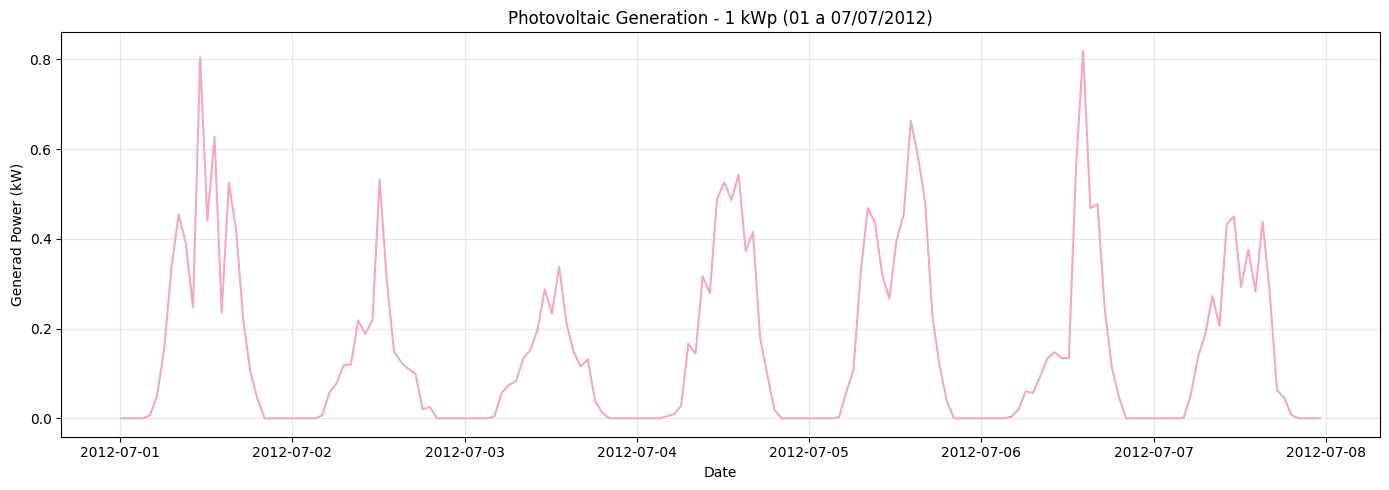

In [13]:
# Seleciona uma semana de dados (35°)
weather_week = weather.loc["2012-07-01":"2012-07-07"]

plt.figure(figsize=(14, 5))

plt.plot(weather_week.index, weather_week["pv_power"] / 1000, label="PV Generation", color="#F8A4C8")

plt.xlabel("Date")
plt.ylabel("Generad Power (kW)")
plt.title("Photovoltaic Generation - 1 kWp (01 a 07/07/2012)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


**Dicas para Comparação: Londres**
- Dia 21/12/2013: dia de inverno com baixa geração PV
- Dia 21/06/2013: dia de verão com alta geração PV

**Gráfico geração diária de Potência DC produzida pelos módulos fotovoltaicos**

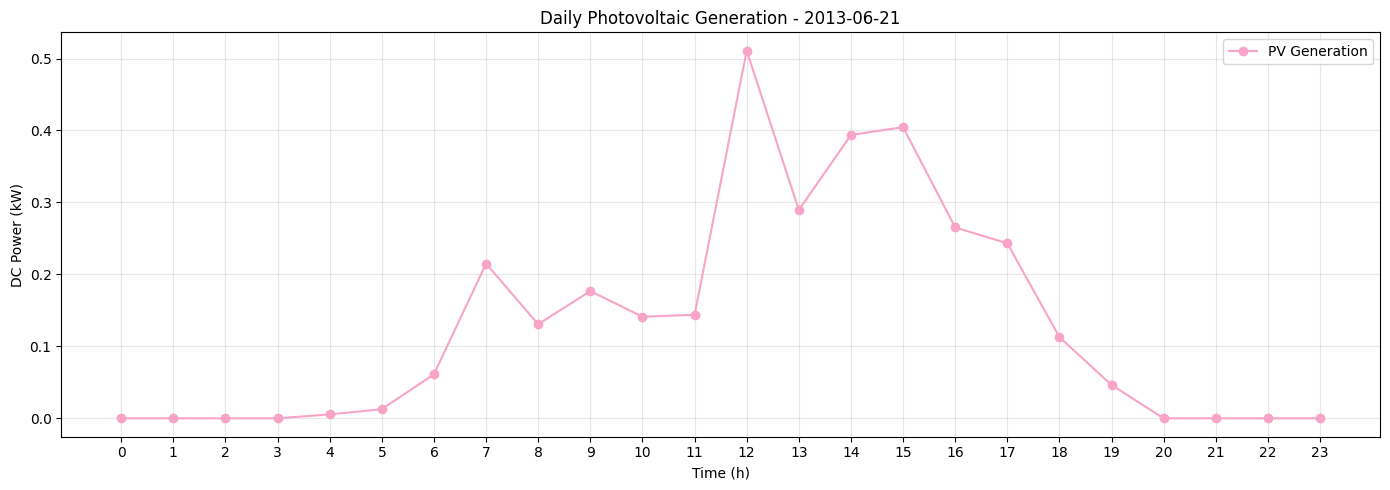

Estimated daily energy: 3.15 kWh


In [14]:

# Gráficos geração PV diários para placas com inclinação de 35°

date = "2013-06-21"
daily_data = weather[weather.index.strftime("%Y-%m-%d") == date]

if daily_data.empty:
    print("Não existem dados para essa data.")
else:
    plt.figure(figsize=(14, 5))

    # Converte potência de W para kW
    plt.plot(
        daily_data.index.hour,
        daily_data["pv_power"] / 1000,
        marker="o",
        label="PV Generation",
        color="#F8A4C8"
    )

    plt.title(f"Daily Photovoltaic Generation - {date}")
    plt.xlabel("Time (h)")
    plt.ylabel("DC Power (kW)")
    plt.xticks(range(0, 24))

    plt.grid(True, alpha=0.3)
    plt.legend()

    plt.tight_layout()
    plt.show()

    daily_energy = daily_data["pv_power"].sum() / 1000

    print(f"Estimated daily energy: {daily_energy:.2f} kWh")


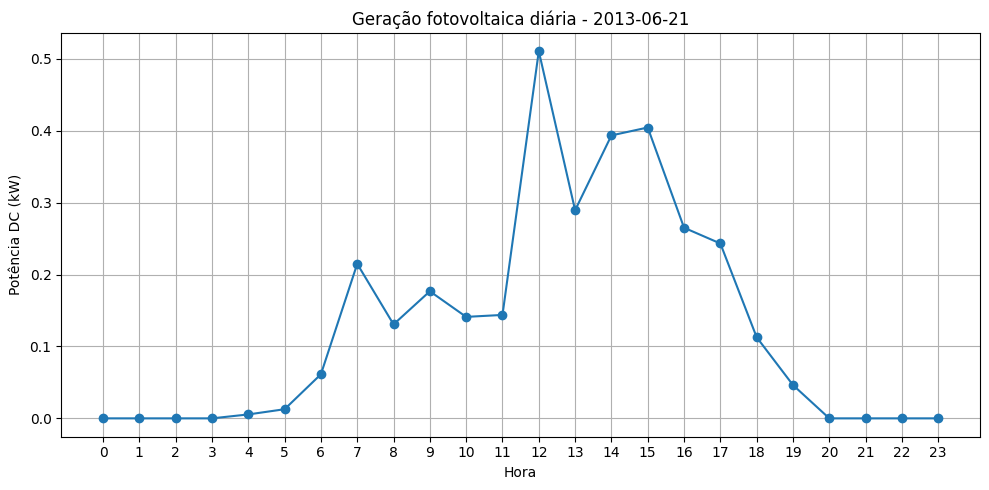

Energia diária estimada: 3.15 kWh


In [35]:
# Referência apenas (NÃO RODAR) Geração Potência DC para inclinação do plano em 0°
date = "2013-06-21"
daily_data = weather[weather.index.strftime("%Y-%m-%d") == date]

if daily_data.empty:
    print("Não existem dados para essa data.")
else:
    plt.figure(figsize=(10, 5))

    # Converte potência de W para kW
    plt.plot(daily_data.index.hour,daily_data["pv_power"] / 1000,marker="o")

    plt.title(f"Geração fotovoltaica diária - {date}")
    plt.xlabel("Hora")
    plt.ylabel("Potência DC (kW)")
    plt.xticks(range(0, 24))
    plt.grid(True)
    plt.tight_layout()
    plt.show()

    daily_energy = daily_data["pv_power"].sum() / 1000

    print(f"Energia diária estimada: {daily_energy:.2f} kWh")

## **Modelagem com o Inversor Fotovoltico**

Conversar potência DC gerada para potência AC

Pac(t) = Pdc(t) . ninv

**Parâmetros do Inversor**

In [15]:
# Eficiência nominal do inversor
eta_inv_nom = 0.96

# Potência nominal AC (W)
pac0_inv = 1000

# Potência nominal de entrada DC do inversor
pdc0_inv = pac0_inv / eta_inv_nom

# Conversão DC para AC utilizando o modelo PVWatts
weather["pv_power_ac"] = pvlib.inverter.pvwatts(
    pdc=weather["pv_power"],
    pdc0=pdc0_inv,
    eta_inv_nom=eta_inv_nom)

# Limita valores negativos a zero
weather["pv_power_ac"] = weather["pv_power_ac"].clip(lower=0)

display(weather[["pv_power", "pv_power_ac"]].head(15))

,pv_power,pv_power_ac
time,,
2012-01-01 00:10:00+00:00,0.000000,0.000000
2012-01-01 01:10:00+00:00,0.000000,0.000000
2012-01-01 02:10:00+00:00,0.000000,0.000000
2012-01-01 03:10:00+00:00,0.000000,0.000000
2012-01-01 04:10:00+00:00,0.000000,0.000000
2012-01-01 05:10:00+00:00,0.000000,0.000000
2012-01-01 06:10:00+00:00,0.000000,0.000000
2012-01-01 07:10:00+00:00,0.000000,0.000000
2012-01-01 08:10:00+00:00,0.000000,0.000000


**Gráficos - Geração PV com inversores fotovoltaicos**




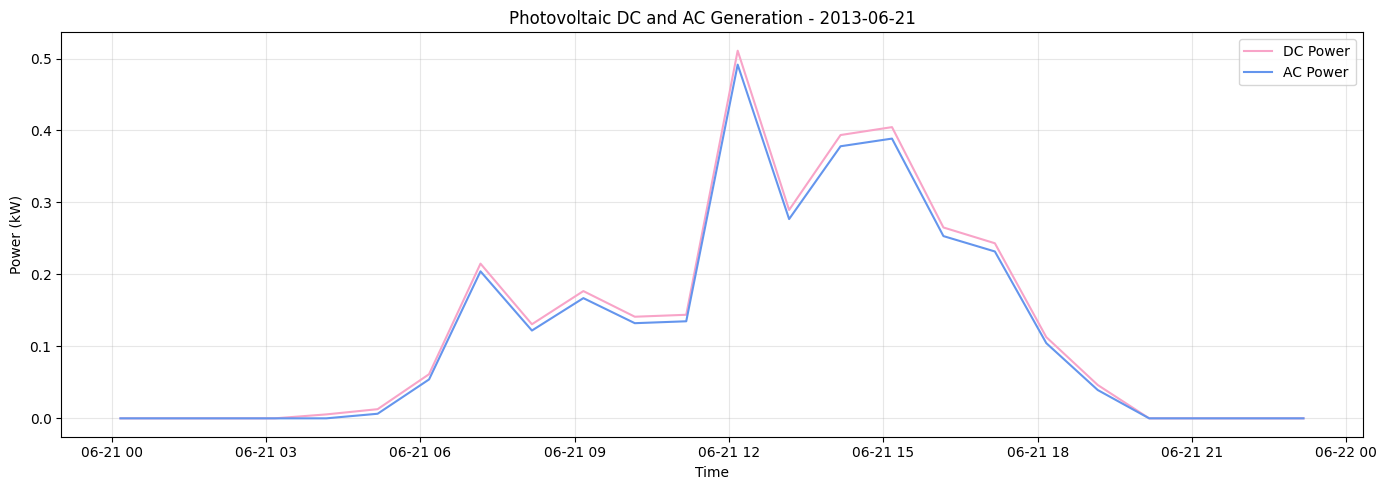

In [16]:
date = "2013-06-21"

daily_data = weather[weather.index.strftime("%Y-%m-%d") == date]
plt.figure(figsize=(14, 5))

plt.plot(daily_data.index,daily_data["pv_power"] / 1000,label="DC Power",color="#F8A4C8")
plt.plot(daily_data.index,daily_data["pv_power_ac"] / 1000,label="AC Power",color="#6495ED")

plt.xlabel("Time")
plt.ylabel("Power (kW)")
plt.title(f"Photovoltaic DC and AC Generation - {date}")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

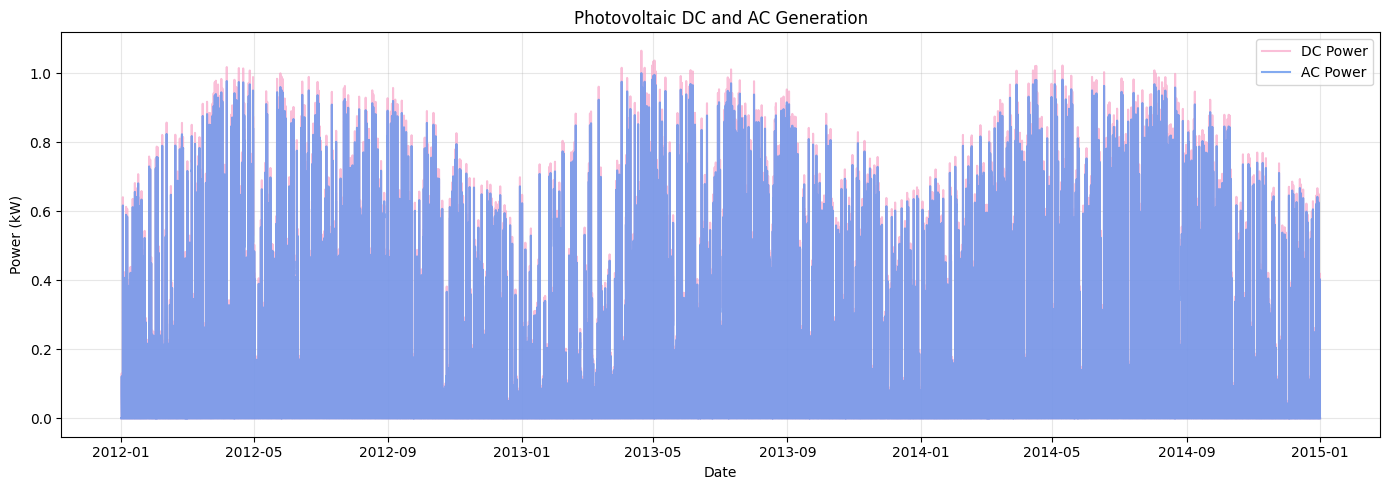

In [17]:
plt.figure(figsize=(14, 5))

plt.plot(weather.index,weather["pv_power"] / 1000,label="DC Power",color="#F8A4C8",alpha=0.7)
plt.plot(weather.index,weather["pv_power_ac"] / 1000,label="AC Power",color="#6495ED",alpha=0.8)

plt.xlabel("Date")
plt.ylabel("Power (kW)")
plt.title("Photovoltaic DC and AC Generation")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### **Normalização dos Dados**

In [18]:
# Normalização da potência fotovoltaica AC
weather["pv_power_ac_norm"] = weather["pv_power_ac"] / 1000
display(weather[["pv_power_ac", "pv_power_ac_norm"]].head(15))

,pv_power_ac,pv_power_ac_norm
time,,
2012-01-01 00:10:00+00:00,0.000000,0.000000
2012-01-01 01:10:00+00:00,0.000000,0.000000
2012-01-01 02:10:00+00:00,0.000000,0.000000
2012-01-01 03:10:00+00:00,0.000000,0.000000
2012-01-01 04:10:00+00:00,0.000000,0.000000
2012-01-01 05:10:00+00:00,0.000000,0.000000
2012-01-01 06:10:00+00:00,0.000000,0.000000
2012-01-01 07:10:00+00:00,0.000000,0.000000
2012-01-01 08:10:00+00:00,0.000000,0.000000


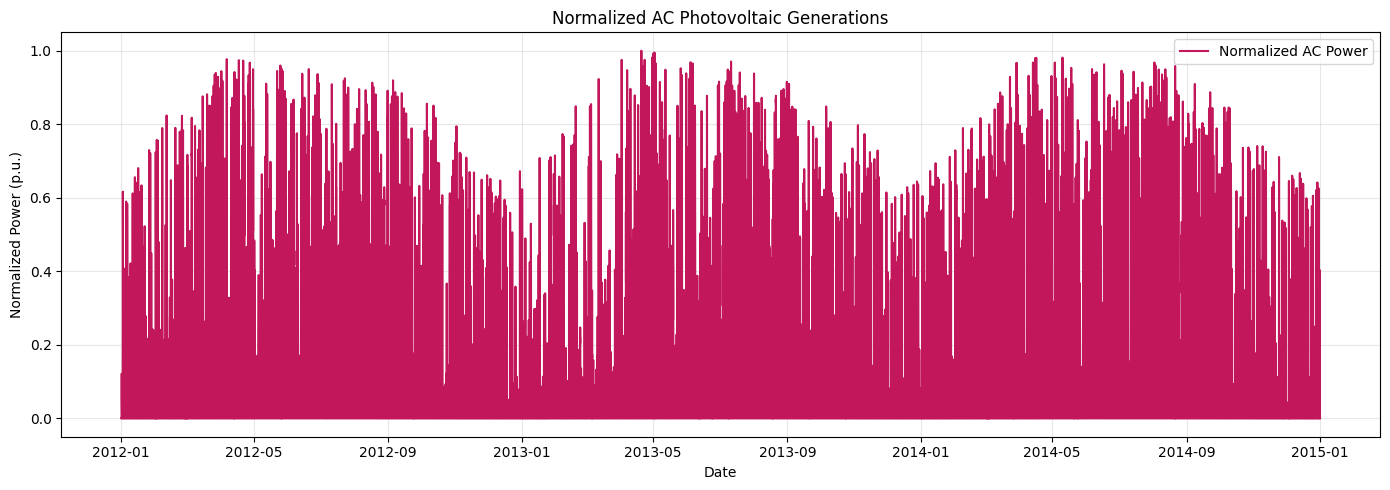

In [19]:
plt.figure(figsize=(14, 5))

plt.plot(weather.index,weather["pv_power_ac_norm"],label="Normalized AC Power",color="#C2185B")

plt.xlabel("Date")
plt.ylabel("Normalized Power (p.u.)")
plt.title("Normalized AC Photovoltaic Generations")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

## **Criação Arquivos Geração PV**

**Interpolação dos dados p/ 15 minutos**



In [22]:
# Interpolação da geração PV para intervalos de 15 minutos

pv_data = weather[["pv_power_ac_norm"]].copy()

# Garantir ordenação temporal
pv_data = pv_data.sort_index()

# Ajustar o índice original para horas cheias
pv_data.index = pv_data.index - pd.Timedelta(minutes=10)

# Criar índice de 15 minutos
new_index = pd.date_range(
    start=pv_data.index.min(),
    end=pv_data.index.max(),
    freq="15min"
)

# Reindexar e interpolar
pv_data = pv_data.reindex(pv_data.index.union(new_index))
pv_data = pv_data.interpolate(method="time")

# Manter somente os horários de 15 minutos
pv_data = pv_data.loc[new_index]

# Transformar índice em coluna
pv_data = pv_data.reset_index()
pv_data = pv_data.rename(columns={"index": "datetime"})

In [23]:
print(pv_data.head(12))

                    datetime  pv_power_ac_norm
0  2012-01-01 00:00:00+00:00               0.0
1  2012-01-01 00:15:00+00:00               0.0
2  2012-01-01 00:30:00+00:00               0.0
3  2012-01-01 00:45:00+00:00               0.0
4  2012-01-01 01:00:00+00:00               0.0
5  2012-01-01 01:15:00+00:00               0.0
6  2012-01-01 01:30:00+00:00               0.0
7  2012-01-01 01:45:00+00:00               0.0
8  2012-01-01 02:00:00+00:00               0.0
9  2012-01-01 02:15:00+00:00               0.0
10 2012-01-01 02:30:00+00:00               0.0
11 2012-01-01 02:45:00+00:00               0.0


**Série Temporal Interpolada Semanal**



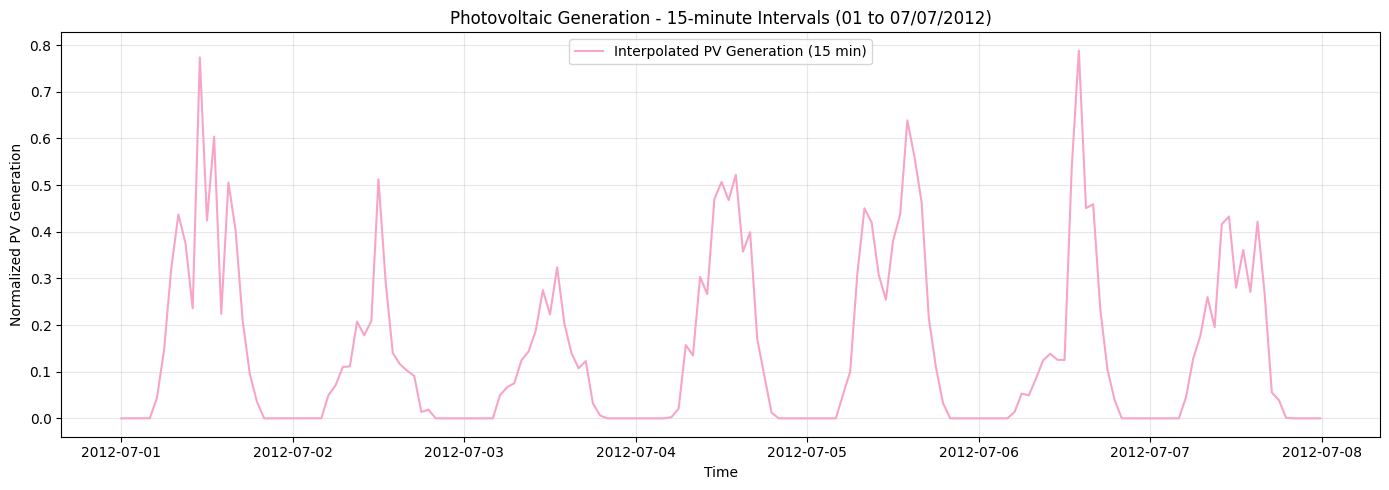

In [24]:
pv_week = pv_data.loc[
    (pv_data["datetime"] >= "2012-07-01") &
    (pv_data["datetime"] < "2012-07-08")]

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

axes.plot(pv_week["datetime"],pv_week["pv_power_ac_norm"],label="Interpolated PV Generation (15 min)",color="#F8A4C8")
axes.set_xlabel("Time")
axes.set_ylabel("Normalized PV Generation")
axes.set_title("Photovoltaic Generation - 15-minute Intervals (01 to 07/07/2012)")
axes.grid(True, alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()

**Série Temporal Interpolada Diária**




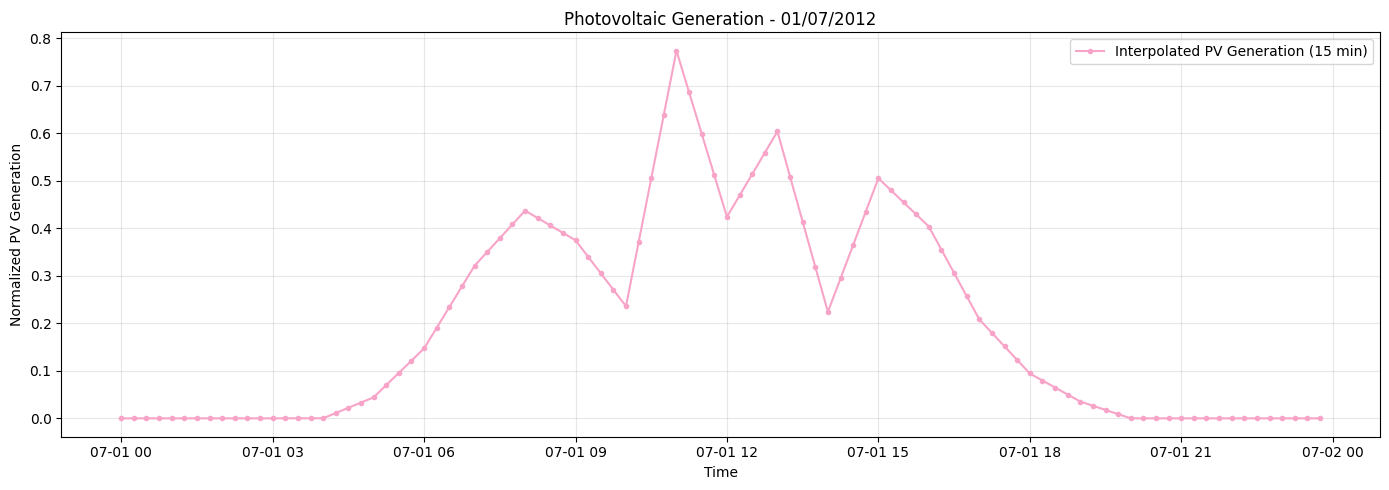

In [25]:

pv_day = pv_data.loc[
    (pv_data["datetime"] >= "2012-07-01") &
    (pv_data["datetime"] < "2012-07-02")
]

fig, axes = plt.subplots(1, 1, figsize=(14, 5))

axes.plot(pv_day["datetime"],pv_day["pv_power_ac_norm"],label="Interpolated PV Generation (15 min)",color="#F8A4C8",marker="o",markersize=3)
axes.set_xlabel("Time")
axes.set_ylabel("Normalized PV Generation")
axes.set_title("Photovoltaic Generation - 01/07/2012")
axes.grid(True, alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()

**Série Temporal Interpolada Completa**





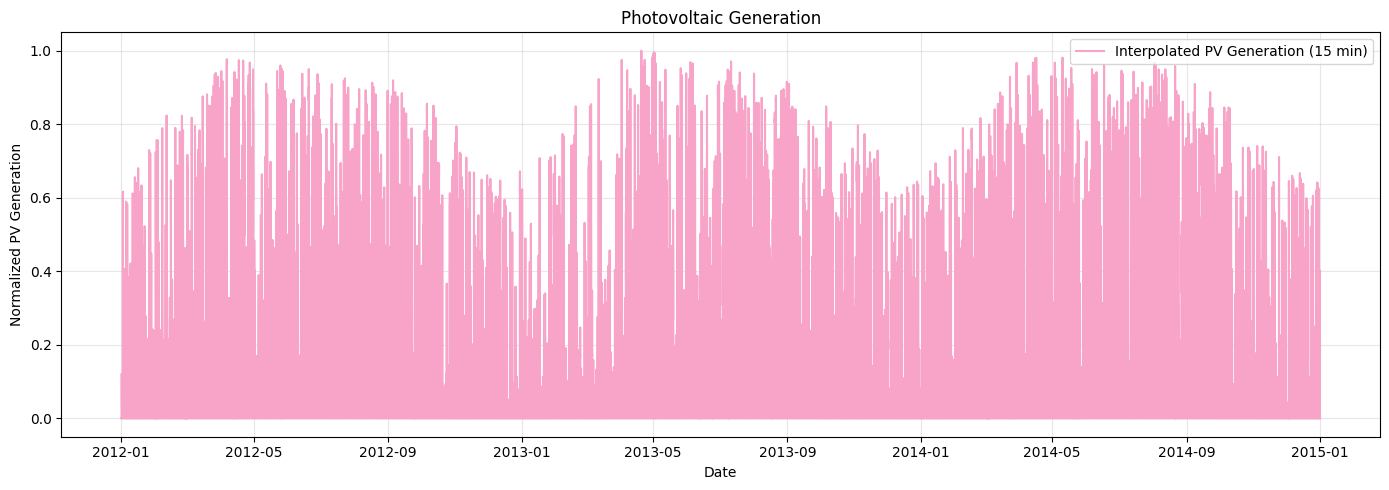

In [26]:
fig, axes = plt.subplots(1, 1, figsize=(14, 5))

axes.plot(pv_data["datetime"],pv_data["pv_power_ac_norm"],label="Interpolated PV Generation (15 min)",color="#F8A4C8")
axes.set_xlabel("Date")
axes.set_ylabel("Normalized PV Generation")
axes.set_title("Photovoltaic Generation")
axes.grid(True, alpha=0.3)
axes.legend()

plt.tight_layout()
plt.show()

**Geração do Arquivo .csv**

In [27]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [28]:
pv_data = pv_data.rename(columns={"pv_power_ac_norm": "power_kWh"})

In [29]:
import os

output_path = "/content/drive/MyDrive/IC-2026/Data_London"

file_name = "pv_generation_London.csv"

pv_data.to_csv(os.path.join(output_path, file_name), index=False)

print("Total de registros:", len(pv_data))
display(pv_data.head(10))

Total de registros: 105213


,datetime,power_kWh
0,2012-01-01 00:00:00+00:00,0.0
1,2012-01-01 00:15:00+00:00,0.0
2,2012-01-01 00:30:00+00:00,0.0
3,2012-01-01 00:45:00+00:00,0.0
4,2012-01-01 01:00:00+00:00,0.0
5,2012-01-01 01:15:00+00:00,0.0
6,2012-01-01 01:30:00+00:00,0.0
7,2012-01-01 01:45:00+00:00,0.0
8,2012-01-01 02:00:00+00:00,0.0
9,2012-01-01 02:15:00+00:00,0.0
